In [ ]:
import sys
print(sys.executable)

c:\Users\HP\OneDrive\Documents\Proactive-Tourism-Recommendation\component3_service\venv\Scripts\python.exe


In [23]:
# Core
import sys
from pathlib import Path
import itertools
from math import sqrt

# Data
import pandas as pd
import numpy as np

# Plotting
import matplotlib.pyplot as plt

# Forecasting
from prophet import Prophet
from sklearn.metrics import mean_squared_error



# ---- Make repo importable (so `configs...` works) ----
repo_root = Path.cwd().resolve()
while repo_root.name != "graphCeylon-API" and repo_root != repo_root.parent:
    repo_root = repo_root.parent
sys.path.insert(0, str(repo_root))

from configs.recommender_service.config import WEATHER_RAW_DIR, DATA_CLEAN_DIR


In [25]:
HISTORY_FILE = WEATHER_RAW_DIR / "cleaned_history.csv"
OUTPUT_FILE  = DATA_CLEAN_DIR / "ai_weather_forecast_optimized.csv"

print(f"Reading data from: {HISTORY_FILE}")
print("Exists?", HISTORY_FILE.exists())


Reading data from: C:\Users\HP\OneDrive\Documents\graphCeylon-API\data\recommender_service\raw\data_raw\weather\cleaned_history.csv
Exists? True


In [26]:
# Check if file exists
if not HISTORY_FILE.exists():
    print(f"❌ Error: History file not found at {HISTORY_FILE}")
    print("Please run 'src.ingestion.historical_loader' first.")
else:
    df = pd.read_csv(HISTORY_FILE)
    df['date'] = pd.to_datetime(df['date'])
    locations = df['location_id'].unique()
    print(f"✅ Loaded {len(df)} records covering {len(locations)} locations.")
    
    # Display the first few rows
    display(df.head())

✅ Loaded 2111 records covering 39 locations.


,date,location_id,avg_temp,rainfall
0,2021-01-01,adam's_peak,15.55,91.4
1,2021-02-01,adam's_peak,15.40,59.2
2,2021-03-01,adam's_peak,16.15,108.7
3,2021-04-01,adam's_peak,16.60,107.2
4,2021-05-01,adam's_peak,17.20,273.2


In [27]:
# --- 3. DEFINE ADVANCED GRID SEARCH ---

# 1. Update Grid with "State of the Art" settings
PARAM_GRID = {
    'changepoint_prior_scale': [0.1, 0.5],       # Removed 0.01 (too stiff for monsoons)
    'seasonality_prior_scale': [10.0],           # 10.0 allows stronger seasonality
    'seasonality_mode': ['additive', 'multiplicative'],  # TEST BOTH! (Crucial for Rain)
    'fourier_order': [10, 20]                    # 10=Smooth, 20=Sharp/Wiggly (Crucial for Peaks)
}

def find_best_params(df, metric_col):
    """
    Runs a grid search to find best Prophet settings for a specific city.
    """
    cut_off = len(df) - 12
    if cut_off < 12:
        # Fallback default if data is too small
        return {
            'changepoint_prior_scale': 0.1, 
            'seasonality_prior_scale': 10.0, 
            'seasonality_mode': 'additive',
            'fourier_order': 10
        }, 0
        
    train_df = df.iloc[:cut_off]
    test_df = df.iloc[cut_off:]
    
    best_params = None
    best_rmse = float('inf')
    
    # Generate all combinations
    keys, values = zip(*PARAM_GRID.items())
    combinations = [dict(zip(keys, v)) for v in itertools.product(*values)]
    
    for params in combinations:
        # Separate 'fourier_order' because it's not a main Prophet arg
        current_fourier = params['fourier_order']
        
        # Prepare params for the constructor (exclude fourier_order)
        model_params = {k: v for k, v in params.items() if k != 'fourier_order'}
        
        # Prepare Data
        prophet_df = train_df[['date', metric_col]].rename(columns={'date': 'ds', metric_col: 'y'})
        
        # --- KEY CHANGE: Disable default yearly_seasonality and add custom one ---
        m = Prophet(
            **model_params, 
            yearly_seasonality=False, # We will add this manually below
            daily_seasonality=False, 
            weekly_seasonality=False
        )
        # Add the custom seasonality (Higher order = sharper peaks)
        m.add_seasonality(name='yearly', period=365.25, fourier_order=current_fourier)
        
        m.fit(prophet_df)
        
        # Validate
        future = m.make_future_dataframe(periods=len(test_df), freq='MS')
        forecast = m.predict(future)
        
        predicted = forecast['yhat'].tail(len(test_df)).values
        actual = test_df[metric_col].values
        
        # Safety for Multiplicative: It can predict huge numbers, check for overflow
        try:
            rmse = sqrt(mean_squared_error(actual, predicted))
        except:
            rmse = float('inf')
        
        if rmse < best_rmse:
            best_rmse = rmse
            best_params = params
            
    return best_params, best_rmse

In [28]:
# --- OUTLIER REMOVAL FUNCTION ---
def cap_outliers(series, z_thresh=3.0):
    """
    Identifies values that are > 3 standard deviations from the mean
    and caps them at the 3-sigma limit.
    """
    mean = series.mean()
    std = series.std()
    
    # Define upper limit (we don't cap lower limit for rain as 0 is natural)
    upper_limit = mean + (z_thresh * std)
    
    # Replace outliers with the upper limit
    # (Using numpy.where is faster and safer than apply)
    capped_series = np.where(series > upper_limit, upper_limit, series)
    
    # Count how many were fixed (for logging)
    n_outliers = np.sum(series > upper_limit)
    
    return capped_series, n_outliers

In [29]:
# --- 4. MAIN OPTIMIZATION LOOP (WITH OUTLIER REMOVAL) ---
print("=== 🚀 Starting Optimized Loop with Outlier Capping ===")

all_forecasts = []
optimization_log = []

for loc in locations:
    # 1. Sort and Interpolate
    loc_df = df[df['location_id'] == loc].sort_values('date')
    
    if len(loc_df) < 12:
        print(f"⚠️ Skipping {loc} (Not enough data)")
        continue

    print(f"📍 Processing: {loc}...")
    
    # Interpolation first (fix missing values)
    loc_df['avg_temp'] = loc_df['avg_temp'].interpolate(limit_direction='both').fillna(method='bfill').fillna(method='ffill')
    loc_df['rainfall'] = loc_df['rainfall'].interpolate(limit_direction='both').fillna(0)
    
    # --- 🛡️ NEW: CAP OUTLIERS ---
    # Fix Rainfall Outliers (Crucial for Yala/Kalpitiya)
    loc_df['rainfall'], rain_caps = cap_outliers(loc_df['rainfall'])
    
    # Fix Temp Outliers (Rare, but good safety)
    loc_df['avg_temp'], temp_caps = cap_outliers(loc_df['avg_temp'])
    
    if rain_caps > 0:
        print(f"   ✂️ Capped {rain_caps} extreme rainfall outliers.")
    
    # --- A. Optimize Temperature ---
    best_params_temp, rmse_temp = find_best_params(loc_df, 'avg_temp')
    temp_fourier = best_params_temp.pop('fourier_order')
    
    m_temp = Prophet(**best_params_temp, yearly_seasonality=False, daily_seasonality=False, weekly_seasonality=False)
    m_temp.add_seasonality(name='yearly', period=365.25, fourier_order=temp_fourier)
    m_temp.fit(loc_df[['date', 'avg_temp']].rename(columns={'date': 'ds', 'avg_temp': 'y'}))
    
    # --- B. Optimize Rainfall ---
    best_params_rain, rmse_rain = find_best_params(loc_df, 'rainfall')
    rain_fourier = best_params_rain.pop('fourier_order')
    
    m_rain = Prophet(**best_params_rain, yearly_seasonality=False, daily_seasonality=False, weekly_seasonality=False)
    m_rain.add_seasonality(name='yearly', period=365.25, fourier_order=rain_fourier)
    m_rain.fit(loc_df[['date', 'rainfall']].rename(columns={'date': 'ds', 'rainfall': 'y'}))
    
    # --- C. Forecast Future ---
    future = m_temp.make_future_dataframe(periods=730) 
    fc_temp = m_temp.predict(future)
    fc_rain = m_rain.predict(future)
    
    # --- D. Save Results ---
    result = pd.DataFrame()
    result['ds'] = fc_temp['ds']
    result['location_id'] = loc
    result['pred_temp'] = fc_temp['yhat'].round(1)
    result['pred_rainfall'] = fc_rain['yhat'].clip(lower=0).round(1)
    
    last_date = loc_df['date'].max()
    result = result[result['ds'] > last_date]
    all_forecasts.append(result)
    
    optimization_log.append({
        'location': loc,
        'temp_rmse': round(rmse_temp, 2),
        'rain_rmse': round(rmse_rain, 2),
        'rain_outliers_capped': rain_caps # Log this for your thesis!
    })

print("✅ Optimization Complete!")

C:\Users\HP\AppData\Local\Temp\ipykernel_1804\3234589423.py:18: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  loc_df['avg_temp'] = loc_df['avg_temp'].interpolate(limit_direction='both').fillna(method='bfill').fillna(method='ffill')
22:27:44 - cmdstanpy - INFO - Chain [1] start processing


=== 🚀 Starting Optimized Loop with Outlier Capping ===
📍 Processing: adam's_peak...


22:27:45 - cmdstanpy - INFO - Chain [1] done processing
22:27:45 - cmdstanpy - INFO - Chain [1] start processing
22:27:45 - cmdstanpy - INFO - Chain [1] done processing
22:27:46 - cmdstanpy - INFO - Chain [1] start processing
22:27:46 - cmdstanpy - INFO - Chain [1] done processing
22:27:46 - cmdstanpy - INFO - Chain [1] start processing
22:27:49 - cmdstanpy - INFO - Chain [1] done processing
22:27:49 - cmdstanpy - INFO - Chain [1] start processing
22:27:49 - cmdstanpy - INFO - Chain [1] done processing
22:27:49 - cmdstanpy - INFO - Chain [1] start processing
22:28:21 - cmdstanpy - INFO - Chain [1] done processing
22:28:21 - cmdstanpy - INFO - Chain [1] start processing
22:28:21 - cmdstanpy - INFO - Chain [1] done processing
22:28:21 - cmdstanpy - INFO - Chain [1] start processing
22:28:53 - cmdstanpy - INFO - Chain [1] done processing
22:28:53 - cmdstanpy - INFO - Chain [1] start processing
22:28:53 - cmdstanpy - INFO - Chain [1] done processing
22:28:54 - cmdstanpy - INFO - Chain [1] 

📍 Processing: adams_peak...


22:28:58 - cmdstanpy - INFO - Chain [1] done processing
22:28:59 - cmdstanpy - INFO - Chain [1] start processing
22:28:59 - cmdstanpy - INFO - Chain [1] done processing
22:28:59 - cmdstanpy - INFO - Chain [1] start processing
22:29:00 - cmdstanpy - INFO - Chain [1] done processing
22:29:00 - cmdstanpy - INFO - Chain [1] start processing
22:29:02 - cmdstanpy - INFO - Chain [1] done processing
22:29:02 - cmdstanpy - INFO - Chain [1] start processing
22:29:02 - cmdstanpy - INFO - Chain [1] done processing
22:29:03 - cmdstanpy - INFO - Chain [1] start processing
22:29:34 - cmdstanpy - INFO - Chain [1] done processing
22:29:34 - cmdstanpy - INFO - Chain [1] start processing
22:29:34 - cmdstanpy - INFO - Chain [1] done processing
22:29:35 - cmdstanpy - INFO - Chain [1] start processing
22:30:06 - cmdstanpy - INFO - Chain [1] done processing
22:30:06 - cmdstanpy - INFO - Chain [1] start processing
22:30:07 - cmdstanpy - INFO - Chain [1] done processing
22:30:07 - cmdstanpy - INFO - Chain [1] 

...

📍 Processing: wilpattu_national_park...


00:00:09 - cmdstanpy - INFO - Chain [1] done processing
00:00:09 - cmdstanpy - INFO - Chain [1] start processing
00:00:10 - cmdstanpy - INFO - Chain [1] done processing
00:00:10 - cmdstanpy - INFO - Chain [1] start processing
00:00:10 - cmdstanpy - INFO - Chain [1] done processing
00:00:11 - cmdstanpy - INFO - Chain [1] start processing
00:00:16 - cmdstanpy - INFO - Chain [1] done processing
00:00:16 - cmdstanpy - INFO - Chain [1] start processing
00:00:17 - cmdstanpy - INFO - Chain [1] done processing
00:00:17 - cmdstanpy - INFO - Chain [1] start processing
00:00:54 - cmdstanpy - INFO - Chain [1] done processing
00:00:55 - cmdstanpy - INFO - Chain [1] start processing
00:00:55 - cmdstanpy - INFO - Chain [1] done processing
00:00:55 - cmdstanpy - INFO - Chain [1] start processing
00:01:33 - cmdstanpy - INFO - Chain [1] done processing
00:01:33 - cmdstanpy - INFO - Chain [1] start processing
00:01:33 - cmdstanpy - INFO - Chain [1] done processing
00:01:33 - cmdstanpy - INFO - Chain [1] 

📍 Processing: yala_national_park...


00:01:50 - cmdstanpy - INFO - Chain [1] done processing
00:01:51 - cmdstanpy - INFO - Chain [1] start processing
00:01:58 - cmdstanpy - INFO - Chain [1] done processing
00:01:58 - cmdstanpy - INFO - Chain [1] start processing
00:02:09 - cmdstanpy - INFO - Chain [1] done processing
00:02:09 - cmdstanpy - INFO - Chain [1] start processing
00:02:28 - cmdstanpy - INFO - Chain [1] done processing
00:02:28 - cmdstanpy - INFO - Chain [1] start processing
00:02:39 - cmdstanpy - INFO - Chain [1] done processing
00:02:39 - cmdstanpy - INFO - Chain [1] start processing
00:02:57 - cmdstanpy - INFO - Chain [1] done processing
00:02:57 - cmdstanpy - INFO - Chain [1] start processing
00:03:08 - cmdstanpy - INFO - Chain [1] done processing
00:03:08 - cmdstanpy - INFO - Chain [1] start processing
00:03:25 - cmdstanpy - INFO - Chain [1] done processing
00:03:25 - cmdstanpy - INFO - Chain [1] start processing
00:03:26 - cmdstanpy - INFO - Chain [1] done processing
00:03:26 - cmdstanpy - INFO - Chain [1] 

✅ Optimization Complete!


In [30]:
if all_forecasts:
    final_forecast = pd.concat(all_forecasts)
    
    # Add Risk Logic
    final_forecast['weather_main'] = final_forecast['pred_rainfall'].apply(lambda x: 'Rain' if x > 50 else 'Clouds')
    final_forecast['risk_level'] = final_forecast['weather_main'].apply(lambda x: 'High' if x == 'Rain' else 'Low')
    
    # Save
    OUTPUT_FILE.parent.mkdir(parents=True, exist_ok=True)
    final_forecast.to_csv(OUTPUT_FILE, index=False)
    print(f"🎉 Saved predictions to {OUTPUT_FILE}")
    
    # Show summary of optimization performance
    print("\n--- Model Performance Summary (RMSE) ---")
    display(pd.DataFrame(optimization_log).head(10))
else:
    print("No forecasts generated.")

🎉 Saved predictions to C:\Users\HP\OneDrive\Documents\graphCeylon-API\data\recommender_service\clean\ai_weather_forecast_optimized.csv

--- Model Performance Summary (RMSE) ---


,location,temp_rmse,rain_rmse,rain_outliers_capped
0,adam's_peak,2.89,114.35,0
1,adams_peak,2.89,114.35,0
2,anuradhapura,0.77,67.31,0
3,arugambay,2.05,209.22,0
4,batticaloa,0.49,46.15,2
5,bentota,0.93,211.75,0
6,beruwela,0.93,211.75,0
7,bundala_national_park,0.49,68.76,2
8,colombo,0.38,178.27,0
9,dambulla,0.00,0.00,0


📊 Visualizing Forecast for: ella


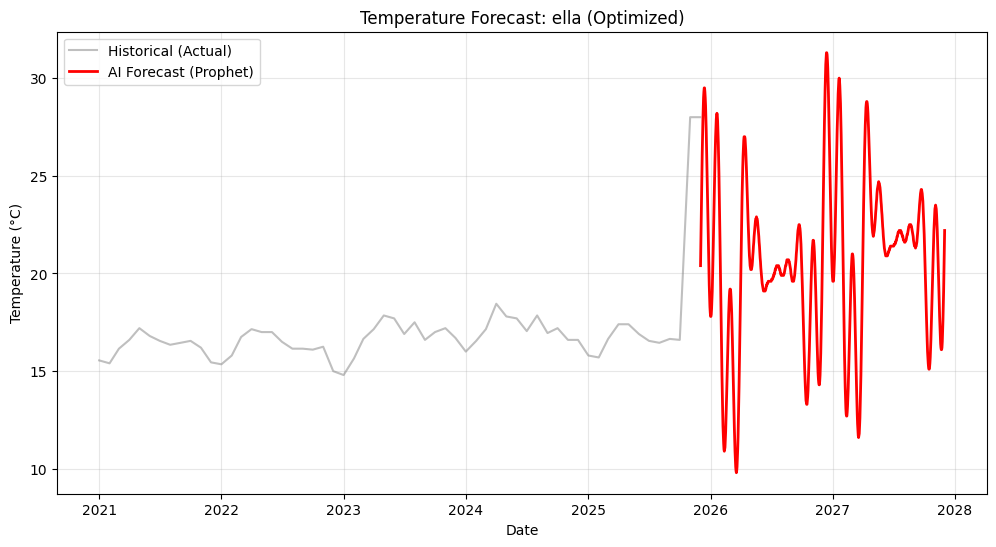

In [31]:
# Change this to any location_id you want to check (e.g., 'ella', 'anuradhapura')
target_loc = 'ella' 

if target_loc not in locations:
    target_loc = locations[0]

print(f"📊 Visualizing Forecast for: {target_loc}")

# Filter data
history_data = df[df['location_id'] == target_loc]
forecast_data = final_forecast[final_forecast['location_id'] == target_loc]

# Plot
plt.figure(figsize=(12, 6))
plt.plot(history_data['date'], history_data['avg_temp'], label='Historical (Actual)', color='gray', alpha=0.5)
plt.plot(forecast_data['ds'], forecast_data['pred_temp'], label='AI Forecast (Prophet)', color='red', linewidth=2)

plt.title(f"Temperature Forecast: {target_loc} (Optimized)")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [32]:
# Convert the optimization log to a DataFrame
log_df = pd.DataFrame(optimization_log)

# Sort by Rainfall Error (Highest first) to find the "worst" predictions
worst_rain_forecasts = log_df.sort_values('rain_rmse', ascending=False).head(5)

print("--- 🌧️ Top 5 Locations with Highest Rainfall Error (RMSE) ---")
display(worst_rain_forecasts)

--- 🌧️ Top 5 Locations with Highest Rainfall Error (RMSE) ---


,location,temp_rmse,rain_rmse,rain_outliers_capped
38,yala_national_park,4.99,369.11,0
5,bentota,0.93,211.75,0
6,beruwela,0.93,211.75,0
3,arugambay,2.05,209.22,0
8,colombo,0.38,178.27,0


In [33]:
# Convert the optimization log to a DataFrame
log_df = pd.DataFrame(optimization_log)

# Sort by Rainfall Error (Highest first) to find the "worst" predictions
best_rain_forecasts = log_df.sort_values('rain_rmse', ascending=True).head(5)

print("--- 🌧️ Top 5 Locations with Lowest Rainfall Error (RMSE) ---")
display(worst_rain_forecasts)

--- 🌧️ Top 5 Locations with Lowest Rainfall Error (RMSE) ---


,location,temp_rmse,rain_rmse,rain_outliers_capped
38,yala_national_park,4.99,369.11,0
5,bentota,0.93,211.75,0
6,beruwela,0.93,211.75,0
3,arugambay,2.05,209.22,0
8,colombo,0.38,178.27,0


📊 Visualizing Forecast for: anuradhapura


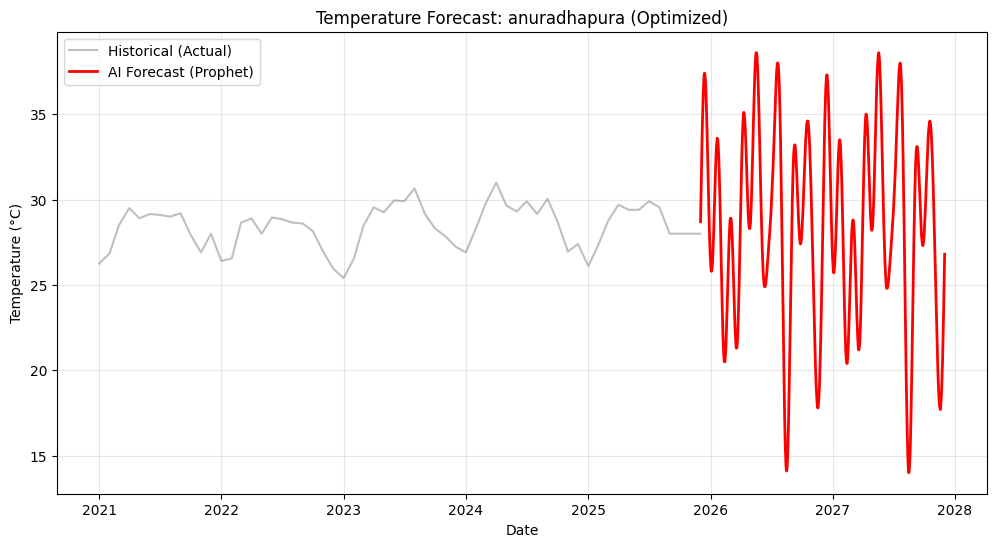

In [34]:
# Change this to any location_id you want to check (e.g., 'ella', 'anuradhapura')
target_loc = 'anuradhapura' 

if target_loc not in locations:
    target_loc = locations[0]

print(f"📊 Visualizing Forecast for: {target_loc}")

# Filter data
history_data = df[df['location_id'] == target_loc]
forecast_data = final_forecast[final_forecast['location_id'] == target_loc]

# Plot
plt.figure(figsize=(12, 6))
plt.plot(history_data['date'], history_data['avg_temp'], label='Historical (Actual)', color='gray', alpha=0.5)
plt.plot(forecast_data['ds'], forecast_data['pred_temp'], label='AI Forecast (Prophet)', color='red', linewidth=2)

plt.title(f"Temperature Forecast: {target_loc} (Optimized)")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()